# 音楽データ拡張の手法

データ拡張(data augmentation)による学習データの「水増し」は、高い汎化性能を持つモデルを作るのに欠かせない手段です。本ページでは音楽情報処理モデルの開発でよく使われる音楽データ拡張の手法を紹介します。

## 基本的なやり方

音楽データを効果的に水増しするには、「**オーディオ処理エフェクトを確率的に適用する**」のが一般的です。この場合、エフェクト適用処理はオンラインで行われるので、学習ループのボトルネックにならないよう処理効率に気を付ける必要があります。GPUによる処理を活用できるよう、GPU転送後のミニバッチ単位で適用する手もあります。

PyTorchベースのデータ拡張ライブラリ`torch-audiomentations`は、GPUを用いた高速なエフェクト適用関数と、確率的にエフェクトを適用する仕組みを用意しています。

In [1]:
import torchaudio
import torch
import numpy as np
from torch_audiomentations import Compose, Gain, PolarityInversion, AddColoredNoise
from IPython.display import Audio, display


apply_augmentation = Compose([
    PolarityInversion(p=0.8, output_type='tensor'),
    AddColoredNoise(min_snr_in_db=3, max_snr_in_db=30, p=0.3, output_type='tensor'),
    Gain(min_gain_in_db=-18, max_gain_in_db=6, p=0.5, output_type='tensor'),
], output_type='tensor')

wav, sr = torchaudio.load("assets/example2.ogg")
wav = wav.unsqueeze(0)
augmented_wav = apply_augmentation.forward(wav, sample_rate=sr)

print("Original audio:")
display(Audio(wav[0].numpy(), rate=sr, normalize=False))
print("Processed audio:")
display(Audio(augmented_wav[0].numpy(), rate=sr, normalize=False))


/home/xiaoming/miniconda3/envs/jupyterbook/lib/python3.11/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Original audio:


Processed audio:


## ピッチシフトとタイムストレッチ

ピッチシフト＝長さを変えずに音の音高を変える（移調）、タイムストレッチ＝音高を変えずに音の長さを変える処理は、幅広い音楽情報処理タスクに使えるデータ拡張手段です。音高やタイミングに注目するタスク（自動採譜・ビート解析など）で使うと、オーディオデータだけでなくラベルデータの多様性も増強する効果があります（シフト量orストレッチ幅に合わせて、ラベルも補正する必要があります）。

一般的に、ピッチシフトはタイムストレッチに基づく処理です（ピッチシフト＝タイムストレッチ＋リサンプリング）。ピッチシフトとタイムストレッチを同時に掛けたい場合、別々に処理するとタイムストレッチを２重でかけることになり、非効率です。タイムストレッチ比とリサンプリング比を目標値から割り出し、1回のタイムストレッチ＋リサンプリングで完結させましょう。

In [2]:

timestretch_transform = torchaudio.transforms.TimeStretch(hop_length=512, n_freq=1025)

def apply_timestretch(wav, timestretch_ratio):
    if timestretch_ratio == 1:
        return wav
    window = torch.hann_window(2048)
    spec = torch.stft(
        input=wav,
        n_fft=2048,
        hop_length=512,
        window=window,
        onesided=True,
        return_complex=True
    )
    spec_stretched = timestretch_transform.forward(spec, 1.0/timestretch_ratio)
    wav_stretched = torch.istft(
        input=spec_stretched,
        n_fft=2048,
        hop_length=512,
        window=window,
        length=round(wav.size(-1) * timestretch_ratio)
    )
    return wav_stretched
    

def apply_timestretch_and_pitchshift(wav, sample_rate, pitchshift_semitones, timestretch_ratio):
    timestretch_rate_for_pitchshift = 2 ** (-float(pitchshift_semitones) / 12)
    timestretch_rate_combined = timestretch_ratio / timestretch_rate_for_pitchshift
    resample_rate = round(sample_rate * timestretch_rate_for_pitchshift)
    if (timestretch_rate_combined != 1):
        # タイムストレッチを適用
        wav = apply_timestretch(wav, timestretch_rate_combined)
    if (pitchshift_semitones != 0):
        # リサンプリング
        wav = torchaudio.functional.resample(wav, sample_rate, resample_rate)
    return wav

# 2半音上にピッチシフトし、1.2倍にタイムストレッチ
augmented_wav = apply_timestretch_and_pitchshift(
    wav[0], sr, pitchshift_semitones=2, timestretch_ratio=1.2
)
print("Original audio:")
display(Audio(wav[0].numpy(), rate=sr, normalize=False))
print("Processed audio:")
display(Audio(augmented_wav.numpy(), rate=sr, normalize=False))

Original audio:


Processed audio:


## フィルター

ローパスフィルターやハイパスフィルターを掛けて、音の帯域を制限します。録音環境やイコライザーによる音色の違いを模擬でき、半教師あり・自己教師あり学習系モデルの学習に多用されています[@won_semisupervised_2021; @choi_contrastive_2022]。

カットオフ周波数は、あらかじめ決めた範囲から一様ランダムに選ぶのが一般的です。ハイパスとローパスのどちらを掛けるかも、確率的に選びます。範囲の例として、[@won_semisupervised_2021]では以下のような範囲を使用しました。
* ハイパスフィルター：200〜1200Hz（低音域を削る）
* ローパスフィルター：2200〜4000Hz（高音域を削る）

## ノイズ追加

音響信号にうっすらノイズを足します。これも自己教師あり学習系モデルで多用されます。

付加するノイズの強さは、信号に対するノイズの振幅比（または SNR [dB]）で指定します。タスクによって差が大きく、ごく弱いノイズ（SNR 40 dB 前後）から、背景音楽を想定した 0〜25 dB 程度まで使われます。

音楽ドメインに特化したモデルを鍛える目的で、ノイズの代わりに「別の音楽オーディオ」を足すケースもあります[@gfeller_spice_2020; @li_mert_2024]。たとえばMERTは、バッチ内の別クリップの一部をランダムな位置に確率的に足す、"**in-batch noise mixup**"というデータ拡張手段を提案しています。

## 残響の付加

部屋の響きを模擬する残響（reverberation）を付加します。残響の少ないスタジオ録音で学習したモデルを、残響の多い実環境の録音に使いたい場合など、録音環境の違いに対する頑健性を高める目的で使われます。ただし、残響は音の立ち上がりを時間方向にぼかすため、音の開始時刻を扱うタスク（オンセット検出など）では、付加する量が大きすぎないよう注意が必要です。

残響を付加する方法は、主に次の2つです。
* **インパルス応答（impulse response, IR）の畳み込み**：実際の部屋や機器で測定したIRを、音声に畳み込みます。`torch-audiomentations`の`ApplyImpulseResponse`が使えますが、IRファイルを別途用意する必要があります。
* **残響エフェクトの適用**：`pedalboard.Reverb`など、IRファイルが不要なエフェクトを使います。

下のコードは、指数減衰するノイズで簡易的なIRを作って畳み込む例です。音が60dB減衰するまでの時間である残響時間（RT60）をランダムに変えれば、さまざまな部屋の響きを模擬できます。FFTによる畳み込みなので、GPU上でも高速に処理できます。

In [3]:
import torch
import torchaudio
from torchaudio.functional import fftconvolve
from IPython.display import Audio, display

torch.manual_seed(0)


def apply_reverb(wav, sample_rate, rt60, wet=0.3):
    # 指数減衰するノイズで簡易的な残響テールを作る（振幅がRT60秒で1/1000=-60dBに減衰）
    n = int(sample_rate * rt60)
    t = torch.arange(n) / sample_rate
    tail = torch.randn(n) * torch.exp(-6.9 * t / rt60)
    tail = tail / tail.norm()

    reverb = fftconvolve(wav, tail.expand(wav.size(0), -1))[..., : wav.size(-1)]
    out = wav + wet * reverb
    # 音量が変わらないよう、RMSを元の音声に合わせる
    return out * (wav.pow(2).mean().sqrt() / out.pow(2).mean().sqrt())


wav, sr = torchaudio.load("assets/example2.ogg")
reverbed_wav = apply_reverb(wav, sr, rt60=0.8)

print("Original audio:")
display(Audio(wav[0].numpy(), rate=sr, normalize=False))
print("Reverb applied (RT60 = 0.8 s):")
display(Audio(reverbed_wav[0].numpy(), rate=sr, normalize=False))

Original audio:


Reverb applied (RT60 = 0.8 s):


## スペクトログラム上のマスキング（SpecAugment）

SpecAugment[@park_specaugment_2019]は、メルスペクトログラムの連続した一部の周波数帯域や時間区間をまとめて隠す（マスクする）手法です。もともとは音声認識向けに提案されましたが、モデルが特定の周波数帯や時間区間だけに頼りすぎるのを防ぐ目的で、音楽のタスクでも使われます。

波形ではなく、モデルへの入力直前の特徴量に適用するため、計算コストはほぼ無視できます。ただし、タスクに必要な情報まで消してしまわないよう、マスク幅の設定に気を付ける必要があります。たとえば、フレームごとのラベルを予測する自動採譜では、マスクした時間区間がノートを丸ごと覆ってしまうと、そのノートを入力から推測できなくなります。

音楽情報処理では、たとえば次のような研究で使われています。
* 音楽タグ付け：Mixupと併用して音楽表現を教師あり学習する[@alonso_efficient_2023]
* 歌詞認識（automatic lyric transcription）：wav2vec 2.0を歌声に転移する際の拡張として使用[@ou_wav2vec_2022]、ピッチと長さを変える拡張PDAugmentと併用[@zhang_pdaugment_2021]
* テンポ推定：自己教師あり学習の事前学習で、周波数方向のマスクをゲインやノイズ付加と併用[@quinton_equivariant_2022]
* 音楽と言語のマルチモーダル事前学習：SLAP[@guinot_slap_2025]では、SpecAugmentが性能をわずかに改善したと報告されています

なお、ビートトラッキング手法Beat This![@foscarin_beat_2024]では、SpecAugmentのようにマスク領域をゼロで埋めるのではなく、マスクする区間（0.5〜2秒）を5〜10個の断片に分けてランダムに並べ替える方法を採用しています。局所的な入力統計を変えずに、音とビートの局所的な対応だけを壊せるため、ゼロ埋めよりも良い結果になったと報告されています。

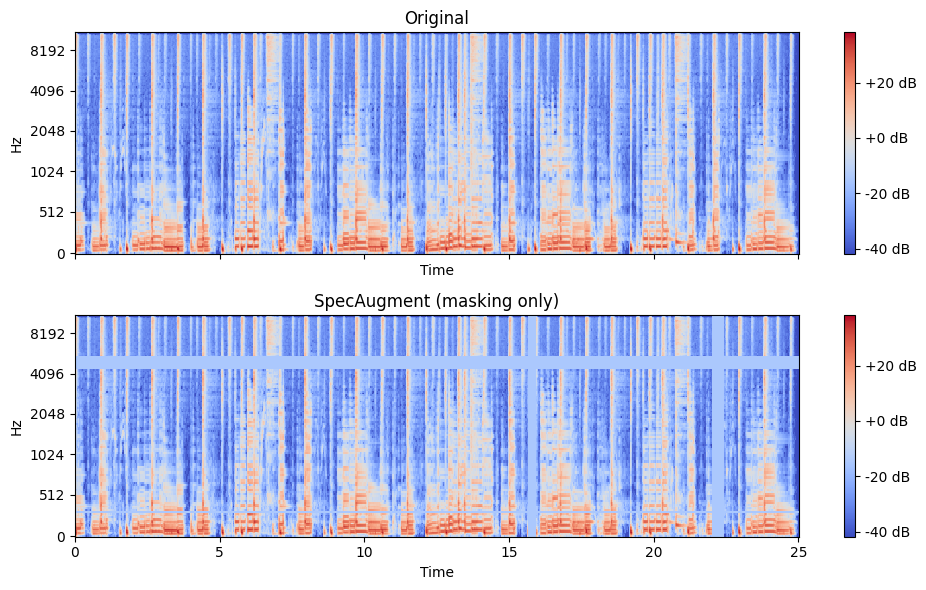

In [4]:
import torch
import torchaudio
import matplotlib.pyplot as plt
import librosa.display

torch.manual_seed(0)

wav, sr = torchaudio.load("assets/example2.ogg")
mel = torchaudio.transforms.MelSpectrogram(
    sample_rate=sr, n_fft=2048, hop_length=512, n_mels=128
)(wav.mean(dim=0))
mel_db = torchaudio.transforms.AmplitudeToDB(stype="power", top_db=80)(mel)

# 周波数方向・時間方向のマスクを、それぞれ2回ずつ適用
spec_augment = [
    torchaudio.transforms.FrequencyMasking(freq_mask_param=20),
    torchaudio.transforms.FrequencyMasking(freq_mask_param=20),
    torchaudio.transforms.TimeMasking(time_mask_param=40),
    torchaudio.transforms.TimeMasking(time_mask_param=40),
]
# dBスケールでは0が無音ではないため、マスク値には全体の平均値を使う
mel_db_masked = mel_db.clone()
for transform in spec_augment:
    mel_db_masked = transform(mel_db_masked, mask_value=float(mel_db.mean()))

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
for ax, spec, title in zip(
    axes, [mel_db, mel_db_masked], ["Original", "SpecAugment (masking only)"]
):
    img = librosa.display.specshow(
        spec.numpy(), sr=sr, hop_length=512, x_axis="time", y_axis="mel", htk=True, ax=ax
    )
    ax.set_title(title)
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.show()

## ステムのランダムミックス

音源分離タスク特有のデータ拡張手法です。異なる楽曲のステムをランダムに選んでミックスすることで、新たな学習サンプルを作ります。非音楽的な学習サンプルが作られるため、音源分離タスクにとってドメイン外のデータを学習に用いることになる（domain mismatch）と思いきや、実際はかなり効果的なテクニックとして知られています。

音楽音源分離モデルに対するランダムミックス手法の効果を詳しく調べた研究[@jeon_cacophony_2024]では、以下のことが示唆されています。
* ランダムミックスは確かに効果的
* オリジナルミックスを学習データに含まなくても（＝ランダムミックスで作成した学習サンプルのみから学習しても）音源分離モデルの性能を損なわない
* 学習サンプル量が同じでも、より多くの楽曲からミックスしたほうがより効果が高い→楽曲データの多様性は重要

## Pedalboardライブラリ

Spotifyが開発しているPythonライブラリ`Pedalboard`([https://github.com/spotify/pedalboard])は、基本的なオーディオエフェクトに加えて、**VST3やAUフォーマットのプラグインエフェクトを適用する**こともできるライブラリです。GPU処理をサポートしないためtorchベースの処理よりも遅くなりますが（それでも頑張って最適化されています）、処理時間が特に重要ではない場面や、ライブラリ独自の機能が必要な場合は、検討する価値はあるでしょう。

たとえば、（データ拡張と少し違いますが）オーディオエフェクトのパラメーター自動推定モデルを鍛えるために使う、エフェクト適用前後のオーディオデータと、エフェクトパラメーターのペアデータ生成に使えます[@steinmetz_stito_2024]。

`pedalboard`のタイムストレッチ＆ピッチシフトアルゴリズムは、オープンソースのC++ライブラリ`Rubber Band`([https://github.com/breakfastquay/rubberband])を用いており、`librosa`や`torchaudio`で実装されているフェーズボコーダー法よりも高音質なタイムストレッチを行うことができます。**フェーズボコーダー法は特に打楽器系の音が崩れやすい**ので、拡張されたデータの音質を重視したい場合は`pedalboard`を使うことも選択肢になります。

In [6]:
import librosa
import pedalboard

wav, sr = librosa.load("assets/example2.ogg", sr=None)


pitch_shift_semitones = 7

wav_shifted_with_librosa = librosa.effects.pitch_shift(
    y=wav,
    sr=sr,
    n_steps=pitch_shift_semitones
)

board = pedalboard.Pedalboard([
    pedalboard.PitchShift(semitones=pitch_shift_semitones)
])

wav_shifted_with_pedalboard = board(wav, sr)

print("Original audio")
display(Audio(wav, rate=sr))
print("Pitch-shifted audio with librosa")
display(Audio(wav_shifted_with_librosa, rate=sr))
print("Pitch-shifted audio with pedalboard")
display(Audio(wav_shifted_with_pedalboard, rate=sr))

Original audio


Pitch-shifted audio with librosa


Pitch-shifted audio with pedalboard
